# 02. Forced photometry on unWISE W1 and W2

The unWISE pixels are 2.75 arcsec across and the PSF is roughly 6 to 7 arcsec
wide, so several Euclid sources usually contribute to one WISE detection.
Forced photometry keeps the VIS positions and shapes fixed, convolves them
with the WISE PSF, and solves for all fluxes and a constant sky together.

The VIS models come from one call to the driver;
[notebook 01](01_nisp_forced_photometry.ipynb) explains how they are
built. The field is the same 200 arcsec region of EDF-N.

In [ ]:
DATA_ACCESS = "DR1"  ## Choose "DR1" or "Q1".
import euclid_phot as ep
ep.set_data_access(DATA_ACCESS)

import time
import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
from astropy.nddata import Cutout2D
import astropy.units as u

from euclid_phot import forced, wise
from euclid_phot.sources import clone_sources
from euclid_phot.tractor_image import make_tractor_image

DATA_DIR = ep.get_data_dir()  ## download cache; set EUCLID_PHOT_DATA_DIR to move it
TARGET_RA, TARGET_DEC = 269.48, 67.30
SIZE_ARCSEC = 100.0  ## memory and run time: README, "Computing cost"
WISE_BANDS = ("W1", "W2")
N_WORKERS = 10

## 1. VIS source models

With no Euclid target bands, `run_forced_photometry` fits only the prior
band: MER positions, the model-selection tree, the bright-star mask, and
the nearest GRID-PSF sample at each source. The fitted source list is
what the WISE fit needs.

In [3]:
t0 = time.time()
vis = ep.run_forced_photometry(
    TARGET_RA, TARGET_DEC, SIZE_ARCSEC,
    prior={"band": "VIS", "objects": "mer", "model_selection": "tree"},
    target_bands={"euclid": (), "wise": ()},
    psf_product="grid", persource_psf=True, mask_bright_stars=True,
    calibrate_errors=False, data_dir=DATA_DIR, n_workers=N_WORKERS,
    force_download=True,
)
sources = vis.sources
fit_quality = vis.flux_quality
print(f"\n{len(sources)} VIS sources in {time.time() - t0:.0f} s; "
      f"{int(fit_quality.sum())} pass the flux guard")

[1/7] query MER catalog at (269.4800, 67.3000)


/Users/ianlin/Desktop/euclid-forced-photometry-dev/src/euclid_phot/pipeline.py:529: UserWarning: DR1 morphology_table is not configured in src/conf.json; Sersic shape columns are masked. The existing source builder uses its isophotal/exponential fallback; tree-selected shapes are still fitted to the VIS pixels.
  result.mer_cat = query_mer_catalog(target_ra, target_dec, half_size_deg)


[2/7] discover mosaics for VIS (lazy; only on a cache miss)
[3/7] fetch cutouts: VIS
[4/7] build per-band PSFs (GRID-PSF, radius=75")
[5/7] build Tractor image + source models on VIS
[5a] STARSIGNAL bright-star mask: 51970 pixels (5.20%) excluded from the VIS fit
[6/7] VIS fit (free, forced-photometry)

557 VIS sources in 159 s; 552 pass the flux guard


## 2. unWISE cutouts

The unWISE cutout extends 60 arcsec beyond the Euclid field on each side,
and the fit region is padded by five WISE FWHM, so that the light of
surrounding sources enters the model. Pixels flagged in the
unWISE bitmask as diffraction spikes, halos, or ghosts are dropped before
solving.

In [4]:
wise_box = max(180.0, SIZE_ARCSEC + 120.0)
tiles = ep.fetch_unwise_cutouts(TARGET_RA, TARGET_DEC, wise_box,
                                data_dir=DATA_DIR / "wise", force_download=True)
print(f"unWISE box: {wise_box:.0f} arcsec, coadd_id={tiles['coadd_id']}, "
      f"W1 shape {tiles['W1']['data'].shape}")
mask = tiles['W1'].get('mask')
if mask is not None:
    n_bad = int(((mask & wise.UNWISE_BAD_BITS) != 0).sum())
    print(f"{n_bad} spike/halo/ghost pixels masked in the box")

unWISE box: 220 arcsec, coadd_id=2709p666, W1 shape (80, 80)
0 spike/halo/ghost pixels masked in the box


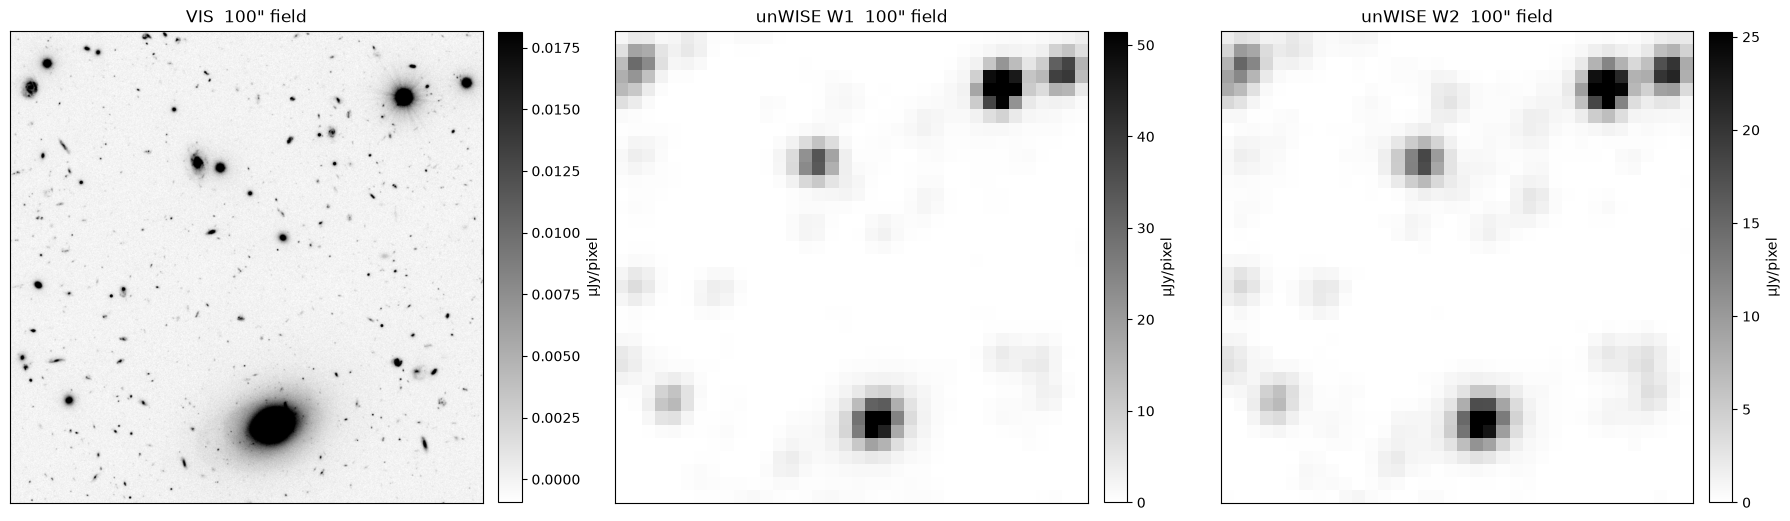

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6.2))
ep.viz.show_cutout(vis.cutouts['VIS'], ax=axes[0], title=f'VIS  {SIZE_ARCSEC:.0f}" field')
for ax, band in zip(axes[1:], WISE_BANDS):
    t = tiles[band]
    cx, cy = t['wcs'].world_to_pixel_values(TARGET_RA, TARGET_DEC)
    cut = Cutout2D(t['data'], (float(cx), float(cy)), SIZE_ARCSEC * u.arcsec, wcs=t['wcs'],
                   mode='partial', fill_value=0.0)
    ujy = ep.viz.ujy_per_unit(band=band)  # µJy per Vega nanomaggy
    ax.imshow(cut.data * ujy, origin='lower', cmap='gray_r', interpolation='nearest',
              vmin=0, vmax=float(np.nanpercentile(cut.data, 99.5)) * ujy)
    ep.viz.add_colorbar(ax, label='µJy/pixel')
    ax.set_title(f'unWISE {band}  {SIZE_ARCSEC:.0f}" field')
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

*The same 200 arcsec field in VIS and in unWISE W1 and W2. One unWISE pixel spans about 27 VIS
pixels, and the PSF about 60, so most VIS sources share their WISE light with neighbours.*

## 3. WISE forced photometry, step by step

Every band in this package runs the same core recipe, and each adds what
its data need. Here it is for W1, where the additions are a constant sky
term and neighbours from outside the Euclid field.

1. **Tractor image.** The fit region is the field padded by five WISE FWHM
   per edge, so the PSF wings of edge sources stay on the pixels. It is cut
   by `wise.unwise_fit_region`, which also gives zero weight to pixels
   flagged as spikes, halos or ghosts. The pixels, their inverse variance,
   the unWISE PSF at the field centre, the WCS and the photometric scale
   are then combined by `make_tractor_image`; unWISE images are in Vega
   nanomaggies, so one AB nanomaggy is $10^{0.4\,\Delta_\mathrm{Vega}}$
   image units.
2. **Source models.** The VIS models are copied into W1 by `clone_sources`,
   with position and shape fixed, a new brightness, and a render patch
   large enough not to crop the 151-pixel PSF. Sources of the unWISE
   catalog (Schlafly et al. 2019) outside the VIS footprint but within the
   PSF wings are added as point sources, so their light is not absorbed by
   the Euclid sources.
3. **Solve.** Everything but the fluxes and a constant sky is frozen with
   `forced.flux_tractor` (small coadd cutouts keep a pedestal), and the
   linear problem is solved by `forced.solve_fluxes`. The `"scaled"` solver
   normalises each template and solves exactly; in dense WISE scenes
   Tractor's default single LSQR update stops short of the solution.
4. **Errors.** Each flux's inverse variance becomes a 1σ error, scaled by
   the robust scatter of (data − model)/σ on pixels with little source
   light, through `forced.chi_inflation`.

The shared-morphology assumption is stronger here than in NISP. A galaxy
that is more compact or more extended in the infrared leaves a structured
residual, close neighbours can exchange flux even when the combined model
looks reasonable, and the reported errors omit that blend covariance.

In [6]:
band = "W1"
wise_psfs = {b: ep.get_wise_psf(int(b[1]), tiles['coadd_id'], ra=TARGET_RA, dec=TARGET_DEC)
             for b in WISE_BANDS}
fit_size = SIZE_ARCSEC + 10 * wise.WISE_FWHM_ARCSEC

# 1. The Tractor image
data, invvar, wcs_fit = wise.unwise_fit_region(tiles[band], TARGET_RA, TARGET_DEC, fit_size)
tim = make_tractor_image(data, invvar, wcs_fit, wise_psfs[band], band=band,
                         nmgy_to_data=10 ** (wise.VEGA_OFFSET[band] / 2.5))

# 2. The VIS models in W1, plus unWISE-catalog neighbours outside the field
band_sources = clone_sources(sources, band,
                             psf_halfsize_pix=wise_psfs[band].shape[0] // 2,
                             pixel_scale_arcsec=wise.UNWISE_PIXEL_SCALE)
neighbours = wise.unwise_neighbours(
    TARGET_RA, TARGET_DEC,
    SkyCoord([s.pos.ra for s in sources], [s.pos.dec for s in sources], unit='deg'),
    field_halfwidth_arcsec=SIZE_ARCSEC / 2,
    buffer_halfwidth_arcsec=fit_size / 2 + 4 * wise.WISE_FWHM_ARCSEC,
    prior_cutout=vis.cutouts['VIS'], catalog_cache_dir=None)
band_sources += wise.neighbour_point_sources(*neighbours, band)

# 3. Solve for the fluxes and a constant sky
tractor = forced.flux_tractor(tim, band_sources, optimizer="scaled", fit_sky=True)
solved = forced.solve_fluxes(tractor, fit_sky=True)

# 4. 1-sigma errors, scaled by the residual scatter
model = tractor.getModelImage(0)
inflation, pool, n_pool = forced.chi_inflation(data, model, invvar,
                                               sky=tim.getSky().getValue())
iv = forced.flux_inverse_variance(solved, tractor, len(band_sources))
step_flux = forced.fluxes_ujy(band_sources, band)[:len(sources)]
step_err = forced.flux_errors_ujy(iv, inflation)[:len(sources)]
print(f"{len(band_sources) - len(sources)} neighbours added; sky = "
      f"{tim.getSky().getValue():+.3f} Vega nMgy/pixel; chi inflation {inflation:.2f} "
      f"from {n_pool} pixels, {pool}")
print(f"S/N > 3 in {np.count_nonzero(step_flux / step_err > 3)}/{len(sources)} VIS sources")

222 neighbours added; sky = -3.293 Vega nMgy/pixel; chi inflation 2.15 from 3589 pixels, all-pixels sigma-clipped fallback
S/N > 3 in 255/557 VIS sources


## 4. Both bands with `fit_wise_forced`

`fit_wise_forced` runs exactly these steps for each band; its W1 fluxes
are the ones above.

In [7]:
t0 = time.time()
wise_results = ep.fit_wise_forced(
    sources, tiles,
    ra=TARGET_RA, dec=TARGET_DEC, cutout_size_arcsec=SIZE_ARCSEC,
    bands=WISE_BANDS, psf_stamps=wise_psfs, prior_cutout=vis.cutouts['VIS'],
    catalog_cache_dir=None,
)
print(f"WISE forced photometry done in {time.time() - t0:.1f} s")
diff = (wise_results['W1']['flux_ujy'] - step_flux) / step_err
print(f"W1: largest difference from the step-by-step fit {np.nanmax(np.abs(diff)):.1e} sigma")
for band in WISE_BANDS:
    r = wise_results[band]
    sn = r['flux_ujy'] / np.where(r['flux_err_ujy'] > 0, r['flux_err_ujy'], np.inf)
    print(f"  {band}: {r['n_supplement_sources']} buffer sources, "
          f"sky={r['sky']:+.3f} nMgy/pix, chi inflation={r['chi_inflation']:.2f}, "
          f"S/N>3 in {int(np.nansum(sn > 3))}/{len(sources)} sources")

WISE forced photometry done in 19.9 s
W1: largest difference from the step-by-step fit 0.0e+00 sigma
  W1: 222 buffer sources, sky=-3.293 nMgy/pix, chi inflation=2.15, S/N>3 in 255/557 sources
  W2: 222 buffer sources, sky=-2.980 nMgy/pix, chi inflation=1.00, S/N>3 in 260/557 sources


## 5. Data, model, and residuals

The full 200 arcsec field in W1 and W2. Data and model share one
brightness scale. The residual is data minus the complete model, sky
included, and the last column divides each pixel by its delivered error.

W1: formal sigma = 0.1753 Vega nMgy, chi std = 15.04 (k = 2.15), |chi|>3 = 18.83%
W2: formal sigma = 0.6262 Vega nMgy, chi std = 3.87 (k = 1.00), |chi|>3 = 7.02%


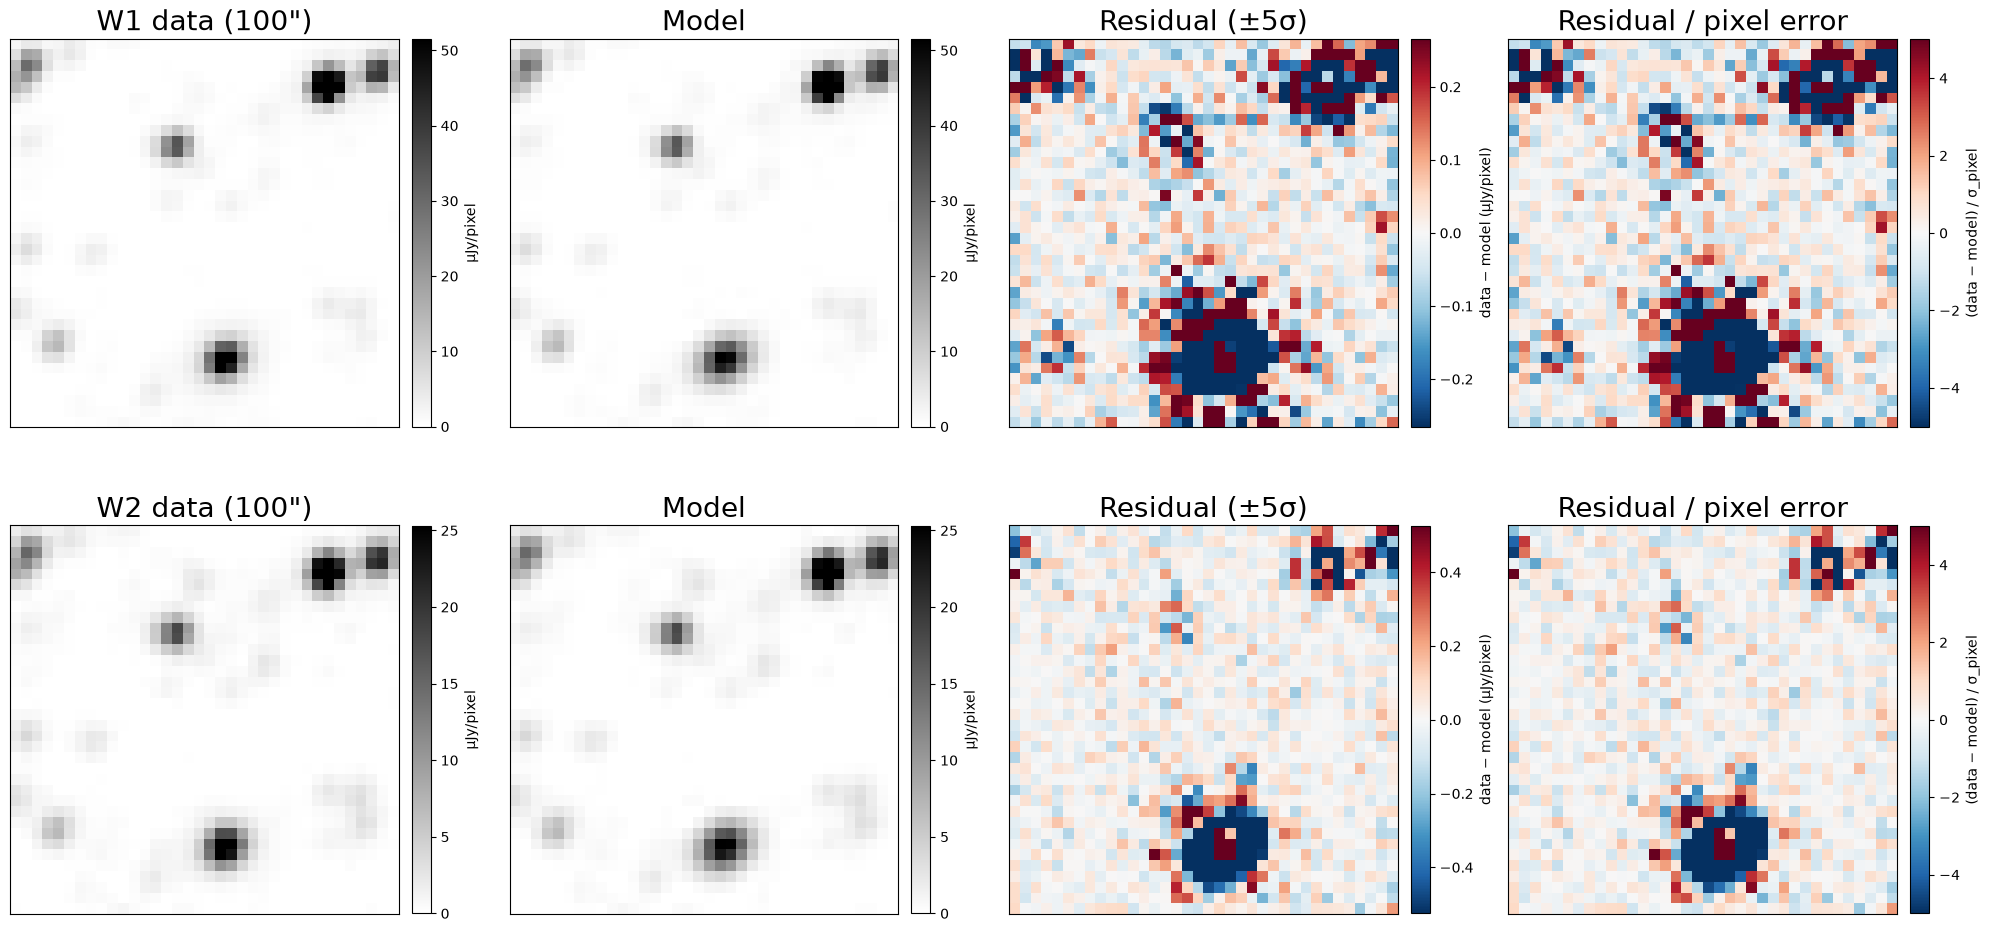

In [8]:
fig, axes = plt.subplots(len(WISE_BANDS), 4, figsize=(20, 5 * len(WISE_BANDS)))
for row, band in enumerate(WISE_BANDS):
    r = wise_results[band]
    cx, cy = r['wcs'].world_to_pixel_values(TARGET_RA, TARGET_DEC)
    box = SIZE_ARCSEC * u.arcsec
    crop = lambda img: Cutout2D(img, (float(cx), float(cy)), box, wcs=r['wcs'],
                                mode='partial', fill_value=0.0).data
    data, model, invvar = crop(r['data']), crop(r['model']), crop(r['invvar'])
    ujy = ep.viz.ujy_per_unit(band=band)  # µJy per Vega nanomaggy
    vmax = float(np.nanpercentile(data, 99.5)) * ujy
    axes[row, 0].imshow(data * ujy, origin='lower', cmap='gray_r', vmin=0, vmax=vmax)
    axes[row, 0].set_title(f'{band} data ({SIZE_ARCSEC:.0f}")')
    axes[row, 1].imshow(model * ujy, origin='lower', cmap='gray_r', vmin=0, vmax=vmax)
    axes[row, 1].set_title('Model')
    for ax in axes[row, :2]:
        ep.viz.add_colorbar(ax, label='µJy/pixel')
    _, info_res = ep.viz.show_residual(data, model, invvar=invvar, scale=ujy,
                                       unit='µJy/pixel', ax=axes[row, 2],
                                       title='Residual (±5σ)')
    _, info_chi = ep.viz.show_chi_map(data, model, invvar,
                                      ax=axes[row, 3], title='Residual / pixel error')
    for ax in axes[row]:
        ax.set_xticks([]); ax.set_yticks([])
        ax.title.set_fontsize(20)
    print(f"{band}: formal sigma = {info_res['formal_sigma']:.4f} Vega nMgy, "
          f"chi std = {info_chi['chi_std']:.2f} (k = {r['chi_inflation']:.2f}), "
          f"|chi|>3 = {info_chi['pct_chi_gt_3']:.2f}%")
plt.tight_layout(); plt.show()

*W1 and W2 over the full field: the data, the model including the sky, the residual, and the
residual divided by the delivered pixel error.*

### Inspect a WISE source

Change `WISE_SOURCE_INDEX` or `WISE_BAND` and rerun the next cell without
refitting. The index follows the Euclid source list. The default pair,
sources 65 and 41, is about 3 arcsec apart and shares one unWISE
detection. Crosses mark the two positions, with fitted fluxes labelled
below; the model includes all sources and the sky. The division of
blended light between such neighbours is sensitive to the source models.

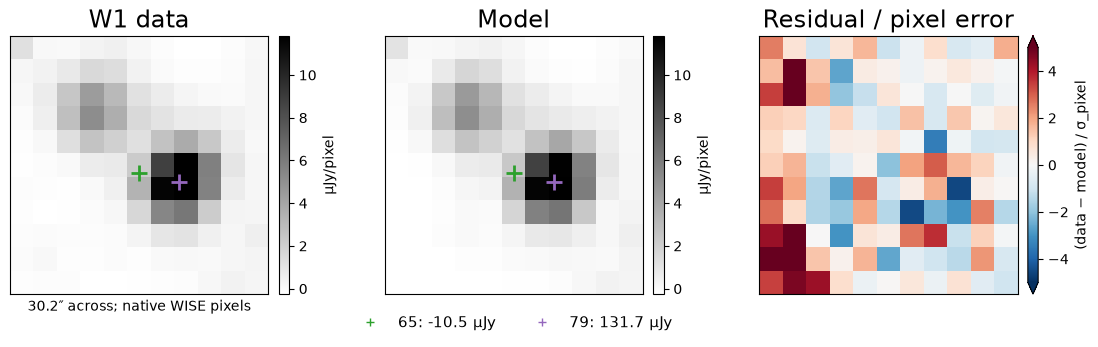

In [9]:
WISE_SOURCE_INDEX = 65
WISE_BAND = "W1"
WISE_SIZE_ARCSEC = 30.0

r = wise_results[WISE_BAND]
xy = np.array([r['wcs'].world_to_pixel_values(s.pos.ra, s.pos.dec) for s in sources])
centre = tuple(xy[WISE_SOURCE_INDEX])
cut = Cutout2D(r['data'], centre, WISE_SIZE_ARCSEC * u.arcsec, wcs=r['wcs'])
sy, sx = cut.slices_original
ujy = ep.viz.ujy_per_unit(band=WISE_BAND)  # µJy per Vega nanomaggy
data, model = r['data'][sy, sx], r['model'][sy, sx]
weight = r['invvar'][sy, sx]
chi = np.where(weight > 0, (data - model) * np.sqrt(weight), np.nan)
extent = (sx.start - .5, sx.stop - .5, sy.start - .5, sy.stop - .5)
lo, hi = np.nanpercentile(data[weight > 0], [1, 99])

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
for ax, im, title in zip(axes, (data * ujy, model * ujy, chi),
                         (f'{WISE_BAND} data', 'Model', 'Residual / pixel error')):
    residual_panel = ax is axes[2]
    shown = ax.imshow(im, origin='lower', extent=extent, interpolation='nearest',
                      cmap='RdBu_r' if residual_panel else 'gray_r',
                      vmin=-5 if residual_panel else lo * ujy,
                      vmax=5 if residual_panel else hi * ujy)
    ax.set_title(title, fontsize=17); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(shown, cax=ax.inset_axes([1.04, 0, .04, 1]),
                 extend='both' if residual_panel else 'neither',
                 label='(data − model) / σ_pixel' if residual_panel else 'µJy/pixel')

# The selected source and its brightest positive neighbour within one FWHM.
distance = np.hypot(*(xy - np.asarray(centre)).T) * wise.UNWISE_PIXEL_SCALE
near = np.flatnonzero((distance < wise.WISE_FWHM_ARCSEC) & (r['flux_ujy'] > 0)
                      & (np.arange(len(sources)) != WISE_SOURCE_INDEX))
highlight = [WISE_SOURCE_INDEX] + ([near[np.argmax(r['flux_ujy'][near])]] if len(near) else [])
for j, colour in zip(highlight, ('tab:green', 'tab:purple')):
    for ax in axes[:2]:
        ax.plot(*xy[j], '+', color=colour, ms=12, mew=2)
    axes[1].plot([], [], '+', color=colour, label=f'{j}: {r["flux_ujy"][j]:.1f} µJy')
axes[1].legend(loc='upper center', bbox_to_anchor=(.5, -.03), ncol=2, fontsize=11, frameon=False)
axes[0].set_xlabel(f'{data.shape[1] * wise.UNWISE_PIXEL_SCALE:.1f}″ across; native WISE pixels')
plt.subplots_adjust(wspace=.45, bottom=.19, right=.9); plt.show()

*A 30 arcsec W1 cutout around the selected source: data, model, and residual over pixel error.
Crosses mark the selected source and its brightest neighbour within one FWHM, with their
fitted fluxes.*

## 6. Cross-check against the Schlafly et al. (2019) unWISE catalog

[Schlafly et al. (2019, ApJS 240, 30), section 5.3](https://ui.adsabs.harvard.edu/abs/2019ApJS..240...30S)
normalize their PSF within 19×19 pixels. For this comparison our
full-stamp fluxes and errors are multiplied by the central 19×19 fraction
of the adopted PSF. This changes the amplitude convention only; the
exported fluxes keep the full-stamp convention.

The comparison uses unique positional matches with primary
detections and no unWISE flags. Sources with no Euclid neighbour brighter
than one third of their VIS flux within two WISE FWHM are highlighted.
Image depth, epochs, source lists, and deblending still differ between
the two measurements.

Schlafly detections: 86; unique matches: 25; VIS-isolated sources: 8
W1: PSF convention factor=0.95174; VIS-isolated S/N>5 n=6, median flux ratio=1.072; reported error ratio=0.30
W2: PSF convention factor=0.95880; VIS-isolated S/N>5 n=6, median flux ratio=1.060; reported error ratio=0.21


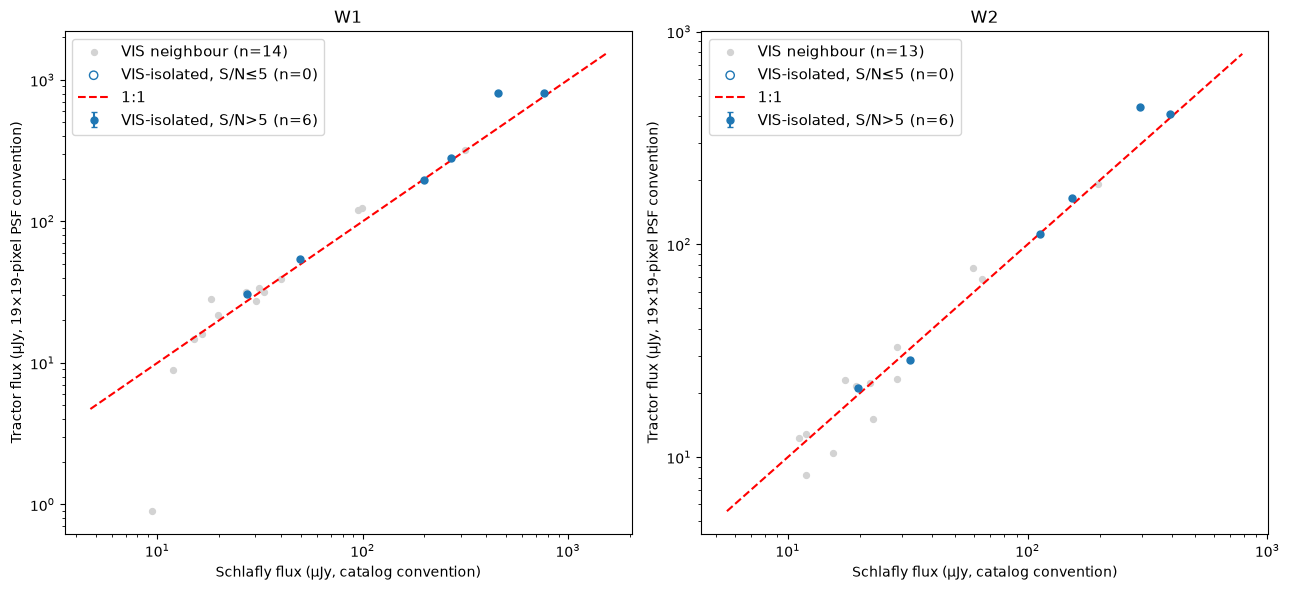

In [10]:
MATCH_RADIUS_ARCSEC = 1.0

vis_cut = vis.cutouts['VIS']
h, w = vis_cut.shape
corner_ra, corner_dec = vis_cut.wcs.pixel_to_world_values([0, 0, w - 1, w - 1], [0, h - 1, 0, h - 1])
query_radius = (SkyCoord(corner_ra, corner_dec, unit='deg').separation(
    SkyCoord(TARGET_RA, TARGET_DEC, unit='deg')).arcsec.max() + MATCH_RADIUS_ARCSEC + 1.0)
uw_cat = ep.query_unwise_2019(TARGET_RA, TARGET_DEC, query_radius,
                              cache_dir=None)

comparisons = ep.compare_unwise_2019(
    sources, wise_results, uw_cat, wise_psfs, vis_flux=vis.fluxes_ujy['VIS'],
    flux_quality=fit_quality, match_radius_arcsec=MATCH_RADIUS_ARCSEC)
first = next(iter(comparisons.values()))
print(f"Schlafly detections: {first.meta['n_catalog']}; unique matches: "
      f"{first.meta['n_unique']}; VIS-isolated sources: {first['isolated'].sum()}")
for band, t in comparisons.items():
    clean = t['clean']
    ratio = np.median(t['flux_ujy'][clean] / t['catalog_flux_ujy'][clean]) if clean.any() else np.nan
    err_ratio = np.median(t['flux_err_ujy'][clean] / t['catalog_flux_err_ujy'][clean]) if clean.any() else np.nan
    print(f"{band}: PSF convention factor={t.meta['psf_factor']:.5f}; VIS-isolated S/N>5 "
          f"n={clean.sum()}, median flux ratio={ratio:.3f}; reported error ratio={err_ratio:.2f}")
ep.viz.show_unwise_comparison(comparisons)
plt.show()

*Our W1 and W2 fluxes against the Schlafly et al. (2019) catalog. Gray points have a bright VIS
neighbour, open circles are VIS-isolated at low S/N, and filled circles VIS-isolated above the
S/N cut. The medians describe the VIS-isolated, S/N > 5 sample. The error ratio
compares the two reported error scales; it does not validate either.*

## 7. Catalog

The WISE fluxes are added to the VIS result and exported with `to_table`. The fluxes keep the full-stamp PSF
convention, which the table metadata records. The saved CSV keeps the rows
with a WISE measurement: identifier, position, model class, the `reliable`
flag, and flux and magnitude with their errors per band.

In [11]:
for band in WISE_BANDS:
    r = wise_results[band]
    vis.fluxes_ujy[band] = np.where(fit_quality, r['flux_ujy'], np.nan)
    vis.flux_errs_ujy[band] = np.where(fit_quality, r['flux_err_ujy'], np.nan)
vis.wise_results = wise_results

catalog = vis.to_table()
print(f"{len(catalog)} sources x {len(catalog.colnames)} columns")
print("WISE flux convention:", catalog.meta.get("wise_flux_convention"))

keep = ['object_id', 'ra', 'dec', 'model', 'reliable'] + [
    c for c in catalog.colnames
    if c.startswith(('flux_', 'mag_')) and not c.endswith(('_extcorr', '_quality'))]
measured = np.isfinite(np.asarray(catalog['flux_W1_ujy'], dtype=float))
catalog[keep][measured].write(f'{DATA_ACCESS}_wise_photometry.csv', overwrite=True)
print(f"wrote {int(measured.sum())} sources x {len(keep)} columns to {DATA_ACCESS}_wise_photometry.csv")

cols = ['object_id', 'ra', 'dec', 'model', 'flux_VIS_ujy',
        'flux_W1_ujy', 'flux_err_W1_ujy', 'mag_W1_ab', 'flux_W2_ujy', 'mag_W2_ab']
preview = catalog[np.isfinite(np.asarray(catalog['flux_W1_ujy']))].copy()
preview.sort('flux_W1_ujy')
preview[cols][-8:].pprint_all()

557 sources x 35 columns
WISE flux convention: Fitted amplitudes with unit-sum finite PSF stamps, converted using the unWISE image zero point and adopted Vega-to-AB offsets. The central-19-pixel transfer is recorded for catalog comparison; it is not applied to these flux columns. Absolute PSF calibration and source-model mismatch are additional uncertainties.
wrote 552 sources x 17 columns to DR1_wise_photometry.csv
     object_id              ra                dec               model             flux_VIS_ujy       flux_W1_ujy       flux_err_W1_ujy       mag_W1_ab         flux_W2_ujy         mag_W2_ab     
                           deg                deg                                     uJy                uJy                 uJy                mag                uJy                mag        
------------------- ------------------ ----------------- -------------------- ------------------- ------------------ ------------------- ------------------ ------------------ -----------------

## 8. Changing the prior: source models from NISP H

The VIS models are the default because VIS has the sharpest PSF, but VIS sees the sources at
0.7 microns and unWISE at 3.4 and 4.6. For red sources, such as dusty or high-redshift galaxies,
the light at 1.8 microns may be distributed differently, and the H image is then the closer guide
to how the light falls in W1 and W2. The cost is the 0.5 arcsec H PSF, which measures the shapes
of small and blended sources less well.

A NISP band is chosen with `prior["band"]`. The model-selection tree and the STARSIGNAL star mask
work on VIS only, so a NISP prior starts from the MER models, refits each galaxy's shape on the
NISP image (`free_shapes`, on by default), and runs without the star mask or with the geometric
one (`mask_bright_stars` as a dict of options). The source list is the same MER catalog either way.

To isolate the effect of the band, the cell below makes two runs that differ only in the prior
band: MER models with shapes refitted on VIS, and the same with shapes refitted on H. Both
measure VIS, H, W1, and W2. The field is 100 arcsec to keep the run to a few minutes; refitting
every shape costs more than the tree on large fields.

In [12]:
PRIOR_TEST_SIZE = 100.0
by_prior = {}
for prior_band in ("VIS", "H"):
    t0 = time.time()
    by_prior[prior_band] = ep.run_forced_photometry(
        TARGET_RA, TARGET_DEC, PRIOR_TEST_SIZE,
        prior={"band": prior_band, "objects": "mer", "model_selection": "prior"},
        target_bands={"euclid": ("VIS", "H"), "wise": WISE_BANDS},
        mask_bright_stars=False, calibrate_errors=False,
        data_dir=DATA_DIR, n_workers=N_WORKERS, force_download=True)
    print(f"{prior_band} prior: {len(by_prior[prior_band].sources)} sources "
          f"in {time.time() - t0:.0f} s")

[1/7] query MER catalog at (269.4800, 67.3000)


/Users/ianlin/Desktop/euclid-forced-photometry-dev/src/euclid_phot/pipeline.py:529: UserWarning: DR1 morphology_table is not configured in src/conf.json; Sersic shape columns are masked. The existing source builder uses its isophotal/exponential fallback; tree-selected shapes are still fitted to the VIS pixels.
  result.mer_cat = query_mer_catalog(target_ra, target_dec, half_size_deg)


[2/7] discover mosaics for VIS, H (lazy; only on a cache miss)
[3/7] fetch cutouts: VIS, H
[4/7] build per-band PSFs (CATALOG-PSF, radius=75")
[5/7] build Tractor image + source models on VIS
[6/7] VIS fit (mer, forced photometry + free shapes)


/Users/ianlin/Desktop/euclid-forced-photometry-dev/src/euclid_phot/pipeline.py:888: UserWarning: step 2 reverted 32 runaway shape(s) to the prior value (radius past the per-source ceiling); fluxes refit with those shapes frozen.
  fit_quality, _ = fit_free_shapes(


[7/7] NISP forced phot: H
[+] WISE forced phot: W1, W2
VIS prior: 557 sources in 227 s
[1/7] query MER catalog at (269.4800, 67.3000)


/Users/ianlin/Desktop/euclid-forced-photometry-dev/src/euclid_phot/pipeline.py:529: UserWarning: DR1 morphology_table is not configured in src/conf.json; Sersic shape columns are masked. The existing source builder uses its isophotal/exponential fallback; tree-selected shapes are still fitted to the VIS pixels.
  result.mer_cat = query_mer_catalog(target_ra, target_dec, half_size_deg)


[2/7] discover mosaics for H, VIS (lazy; only on a cache miss)
[3/7] fetch cutouts: H, VIS
[4/7] build per-band PSFs (CATALOG-PSF, radius=75")
[5/7] build Tractor image + source models on H
[6/7] H fit (mer, forced photometry + free shapes)


/Users/ianlin/Desktop/euclid-forced-photometry-dev/src/euclid_phot/pipeline.py:888: UserWarning: step 2 reverted 21 runaway shape(s) to the prior value (radius past the per-source ceiling); fluxes refit with those shapes frozen.
  fit_quality, _ = fit_free_shapes(


[7/7] NISP forced phot: VIS
[+] WISE forced phot: W1, W2
H prior: 557 sources in 192 s


The ratio of the W1 and W2 fluxes from the H models to those from the VIS models, against
the VIS − H colour from the VIS-model run. Sources with S/N above 5 in both runs are shown, and
the printed table gives the median and NMAD of the ratio in colour bins.

W1: median ratio 0.977, n=192; 146 differ by more than 5% (87 lower with H models)
   VIS - H in [-inf, +0.5): n= 23, median 0.914, NMAD 0.333
   VIS - H in [+0.5, +1.0): n= 55, median 0.974, NMAD 0.265
   VIS - H in [+1.0, +1.5): n= 66, median 0.981, NMAD 0.198
   VIS - H in [+1.5, +inf): n= 48, median 0.987, NMAD 0.116
W2: median ratio 0.994, n=178; 122 differ by more than 5% (66 lower with H models)
   VIS - H in [-inf, +0.5): n= 25, median 1.016, NMAD 0.425
   VIS - H in [+0.5, +1.0): n= 54, median 0.979, NMAD 0.174
   VIS - H in [+1.0, +1.5): n= 53, median 1.001, NMAD 0.127
   VIS - H in [+1.5, +inf): n= 46, median 0.998, NMAD 0.115


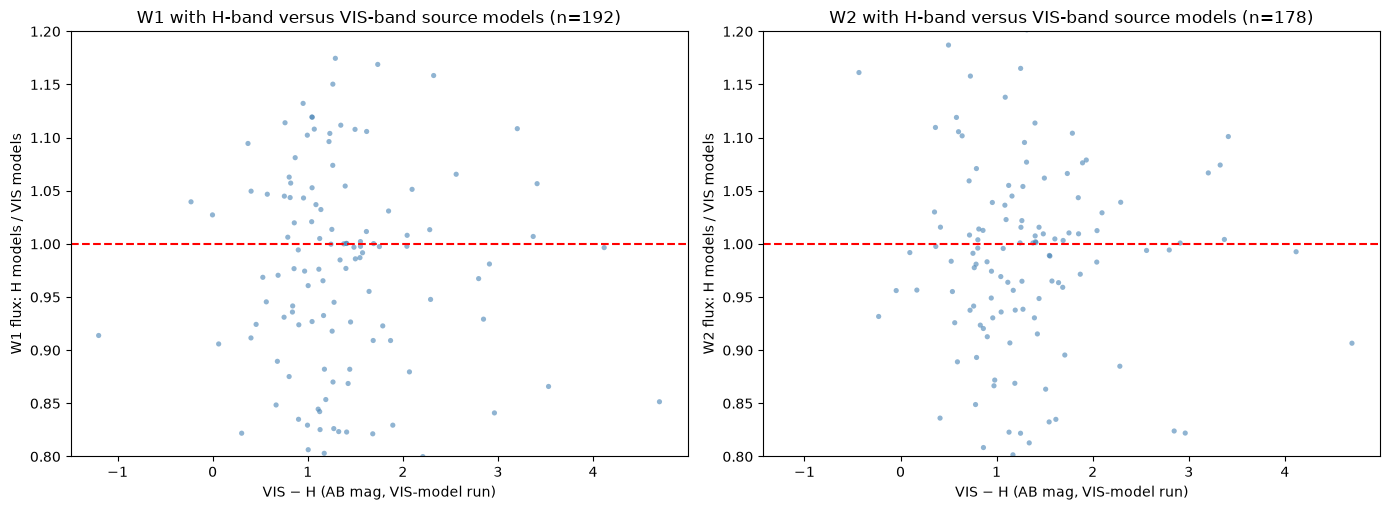

In [13]:
from astropy.stats import mad_std

f_vis, e_vis = by_prior["VIS"].fluxes_ujy, by_prior["VIS"].flux_errs_ujy
f_h, e_h = by_prior["H"].fluxes_ujy, by_prior["H"].flux_errs_ujy
with np.errstate(divide='ignore', invalid='ignore'):
    colour = -2.5 * np.log10(f_vis["VIS"] / f_vis["H"])

fig, axes = plt.subplots(1, len(WISE_BANDS), figsize=(7 * len(WISE_BANDS), 5.2), squeeze=False)
bins = (-np.inf, 0.5, 1.0, 1.5, np.inf)
for ax, band in zip(axes[0], WISE_BANDS):
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = f_h[band] / f_vis[band]
        ok = ((f_vis[band] / e_vis[band] > 5) & (f_h[band] / e_h[band] > 5)
              & np.isfinite(colour))
    ax.scatter(colour[ok], ratio[ok], s=14, c='steelblue', alpha=0.6, edgecolors='none')
    ax.axhline(1.0, color='r', ls='--', lw=1.5)
    ax.set(xlabel='VIS − H (AB mag, VIS-model run)',
           ylabel=f'{band} flux: H models / VIS models',
           title=f'{band} with H-band versus VIS-band source models (n={int(ok.sum())})',
           ylim=(0.8, 1.2))
    off = ok & (np.abs(ratio - 1) > 0.05)
    print(f"{band}: median ratio {np.median(ratio[ok]):.3f}, n={int(ok.sum())}; "
          f"{int(off.sum())} differ by more than 5% ({int(np.sum(off & (ratio < 1)))} lower with H models)")
    for lo, hi in zip(bins[:-1], bins[1:]):
        sel = ok & (colour >= lo) & (colour < hi)
        if sel.sum() >= 5:
            print(f"   VIS - H in [{lo:+.1f}, {hi:+.1f}): n={int(sel.sum()):3d}, "
                  f"median {np.median(ratio[sel]):.3f}, NMAD {mad_std(ratio[sel]):.3f}")
plt.tight_layout(); plt.show()

*The W1 and W2 fluxes measured with source models refitted on H, divided by those with models
refitted on VIS, against the VIS − H colour. The dashed line marks equal fluxes; points outside
0.8 to 1.2 are off the plot.*

For most sources the choice of prior band changes the unWISE flux by a few percent or less, and
the median ratio is one in every colour bin: the 6 arcsec unWISE PSF smooths away most of the
difference between shapes measured at 0.5 and 0.2 arcsec resolution. A minority, printed above,
differ by more than 5 percent, mostly coming out fainter with the H models, and they are not
concentrated among the reddest sources. A source missing from the MER catalog is missing from
both runs: the choice of prior band changes the models, not the source list.

### Which models describe the discrepant sources better?

Both runs fit the same unWISE pixels with the shapes fixed and only the fluxes free, so the
residuals can decide between them, if the data constrain the difference. The cell below takes
every source whose W1 flux changes by more than 5 percent and compares the two fits around it.
For each run it gives the reduced chi-squared within 6 arcsec, one unWISE FWHM, divided by the
square of the residual-scatter factor $k$ of section 3, so that it is close to one where a model
fits. It then splits the chi-squared gain of the H models between the core of the source, within
3 arcsec, and the ring from 3 to 6 arcsec, where the neighbours contribute; and it gives the
largest difference between the two model images in the core, in units of the pixel noise.

In [14]:
BAND = "W1"
imgs = {pb: {b: by_prior[pb].image_set(b) for b in ("VIS", "H", BAND)} for pb in by_prior}
flux = {pb: by_prior[pb].fluxes_ujy for pb in by_prior}
err = {pb: by_prior[pb].flux_errs_ujy for pb in by_prior}
models = {pb: by_prior[pb].chosen_models for pb in by_prior}
assert all(by_prior["VIS"].mer_cat["object_id"] == by_prior["H"].mer_cat["object_id"])
ra = np.array([s.getPosition().ra for s in by_prior["VIS"].sources])
dec = np.array([s.getPosition().dec for s in by_prior["VIS"].sources])
k2 = np.mean([by_prior[pb].wise_results[BAND]["chi_inflation"] for pb in by_prior]) ** 2

yy, xx = np.indices(imgs["VIS"][BAND]["data"].shape)
xw, yw = imgs["VIS"][BAND]["wcs"].world_to_pixel_values(ra, dec)
pix_arcsec = 2.75
with np.errstate(divide='ignore', invalid='ignore'):
    ratio = flux["H"][BAND] / flux["VIS"][BAND]
    ok = ((flux["VIS"][BAND] / err["VIS"][BAND] > 5) & (flux["H"][BAND] / err["H"][BAND] > 5)
          & np.isfinite(colour))
offset = np.flatnonzero(ok & (np.abs(ratio - 1) > 0.05))

iv_w = imgs["VIS"][BAND]["invvar"]
# Per pixel, chi2 with VIS models minus chi2 with H models (after k^2): positive where H fits better.
chi2_gain = np.where(iv_w > 0, (imgs["VIS"][BAND]["residual"]**2
                                - imgs["H"][BAND]["residual"]**2) * iv_w / k2, np.nan)
model_diff = np.where(iv_w > 0, (imgs["H"][BAND]["model"] - imgs["VIS"][BAND]["model"])
                      * np.sqrt(iv_w), np.nan)

rows = []
for i in offset:
    d2 = ((xx - xw[i])**2 + (yy - yw[i])**2) * pix_arcsec**2
    circle = (d2 < 6.0**2) & (iv_w > 0)
    core = (d2 < 3.0**2) & (iv_w > 0)
    rchi2 = {pb: float(np.sum(imgs[pb][BAND]["residual"][circle]**2 * iv_w[circle])) / k2 / circle.sum()
             for pb in ("VIS", "H")}
    rows.append(dict(i=i, ratio=ratio[i], colour=colour[i], VIS=rchi2["VIS"], H=rchi2["H"],
                     core=float(np.nansum(chi2_gain[core])),
                     ring=float(np.nansum(chi2_gain[circle & ~core])),
                     max_diff=float(np.nanmax(np.abs(model_diff[core])))))

print(f"{BAND}: {len(rows)} of {int(ok.sum())} sources differ by more than 5%")
print(f"{'source':>6s} {'H/VIS':>6s} {'VIS-H':>6s} {'rchi2 VIS':>10s} {'rchi2 H':>8s} "
      f"{('gain <3' + chr(34)):>9s} {('gain 3-6' + chr(34)):>10s} {'max|dmodel|':>12s}")
for r in rows:
    print(f"{r['i']:6d} {r['ratio']:6.2f} {r['colour']:+6.2f} {r['VIS']:10.2f} {r['H']:8.2f} "
          f"{r['core']:+9.2f} {r['ring']:+10.2f} {r['max_diff']:10.2f} σ")
fits = [r for r in rows if min(r["VIS"], r["H"]) < 2.0]
print(f"\nneither set of models fits within 6 arcsec (reduced chi2 > 2): {len(rows) - len(fits)}")
print(f"of the other {len(fits)}: chi2 gain of the H models within 3 arcsec "
      f"{sum(r['core'] for r in fits):+.1f} in total, positive for {sum(r['core'] > 0 for r in fits)}; "
      f"from 3 to 6 arcsec {sum(r['ring'] for r in fits):+.1f}")

W1: 146 of 192 sources differ by more than 5%
source  H/VIS  VIS-H  rchi2 VIS  rchi2 H  gain <3"  gain 3-6"  max|dmodel|
     3   0.60  +2.75       2.54     3.37     -0.48     -12.89       0.50 σ
     5   0.50  +1.75       0.37     0.36     -0.93      +1.03       0.54 σ
     9   0.79  +2.68       0.17     0.19     +0.12      -0.42       0.11 σ
    17   0.58  +0.70       1.71     0.83     +3.21     +10.10       1.15 σ
    21   0.78  +1.41       3.86     3.60     -1.18      +5.04       0.46 σ
    23   1.45  +0.97       0.27     0.31     +0.00      -0.58       0.13 σ
    25   1.06  +0.80       0.55     0.39     +0.14      +2.38       0.22 σ
    28   1.40  +1.29       0.89     0.50     -0.36      +6.09       0.33 σ
    30   1.06  +3.41       8.95     9.06     -0.96      -0.68       0.37 σ
    41   0.65  +0.23       0.27     0.27     +0.13      -0.02       0.24 σ
    43   0.85  +4.70       0.60     0.52     +0.21      +0.85       0.17 σ
    44   0.49  +2.27       0.77     1.06     -0.51    

The four sources with the largest chi-squared difference among those where at least one set of
models fits: VIS, H, and W1 data; the difference between the two W1 model images in units of the
pixel noise; and the per-pixel chi-squared gain of the H models. The dotted and dashed circles
are 3 and 6 arcsec in radius; the green cross marks the source and the orange crosses its MER
neighbours.

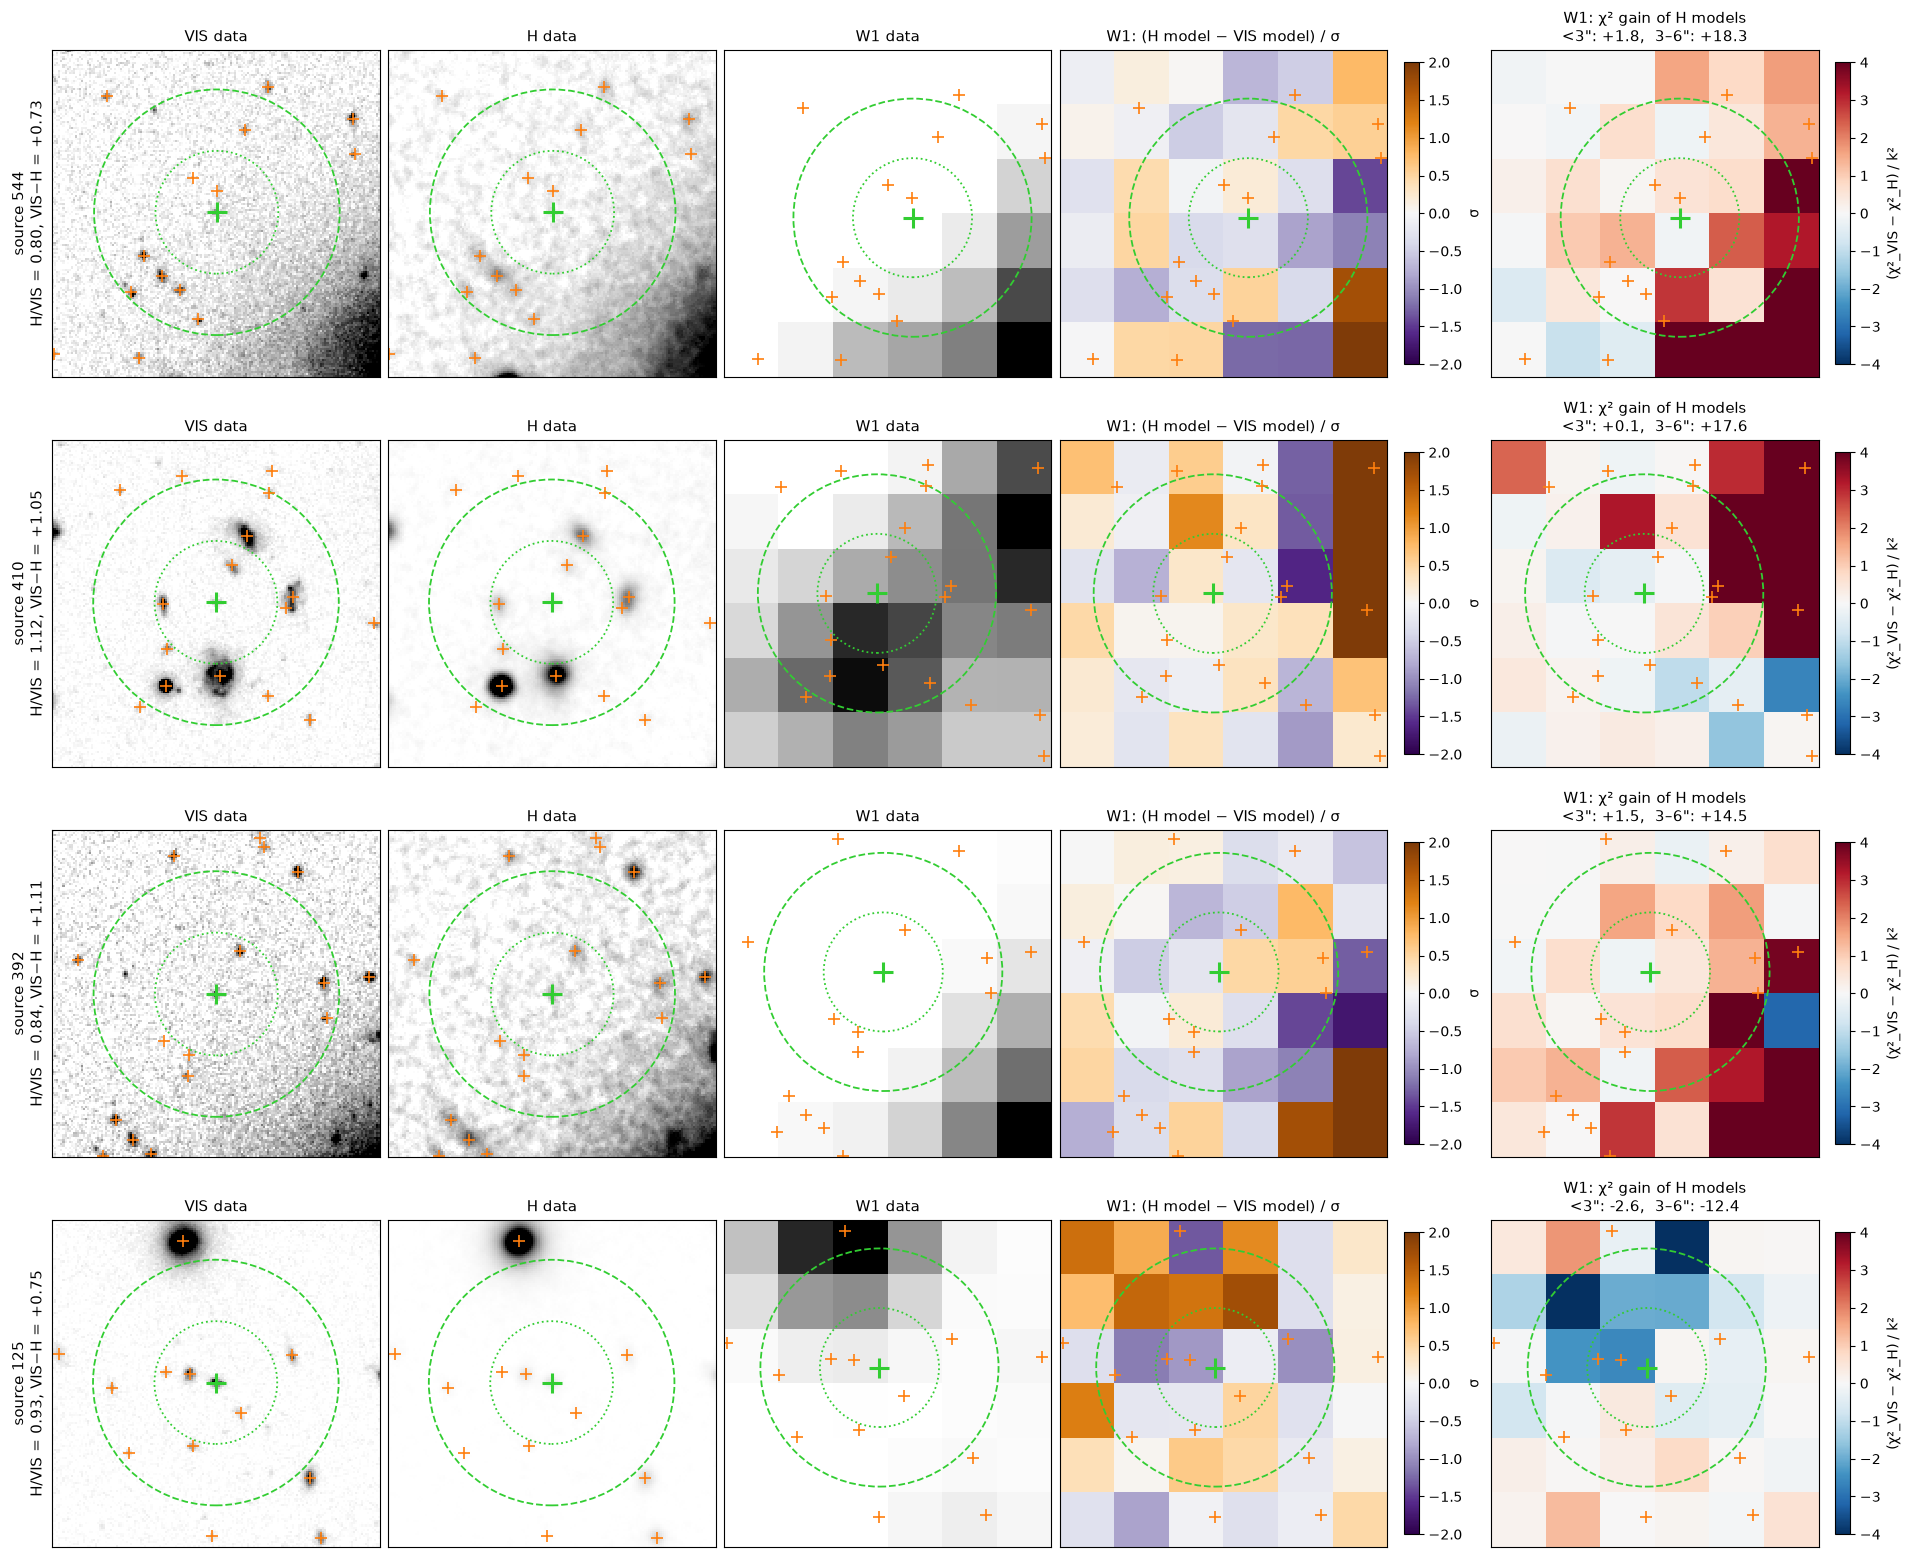

In [15]:
from matplotlib.patches import Circle
STAMP = 16.0  # arcsec
show = sorted(fits, key=lambda r: -abs(r["core"] + r["ring"]))[:4]
fig, axes = plt.subplots(len(show), 5, figsize=(19, 3.9 * len(show)), squeeze=False,
                         constrained_layout=True)
wcs_w = imgs["VIS"][BAND]["wcs"]
for row, src in zip(axes, show):
    i = src["i"]
    pos = SkyCoord(ra[i], dec[i], unit='deg')
    panels = [(f"{b} data", Cutout2D(imgs["VIS"][b]["data"], pos, STAMP * u.arcsec,
                                     wcs=imgs["VIS"][b]["wcs"], mode='partial', fill_value=0), "data")
              for b in ("VIS", "H", BAND)]
    panels.append((f"{BAND}: (H model − VIS model) / σ",
                   Cutout2D(model_diff, pos, STAMP * u.arcsec, wcs=wcs_w, mode='partial',
                            fill_value=np.nan), "diff"))
    panels.append((f"{BAND}: χ² gain of H models\n<3\": {src['core']:+.1f},  3–6\": {src['ring']:+.1f}",
                   Cutout2D(chi2_gain, pos, STAMP * u.arcsec, wcs=wcs_w, mode='partial',
                            fill_value=np.nan), "gain"))
    for ax, (title, cut, kind) in zip(row, panels):
        if kind == "data":
            ax.imshow(cut.data, origin='lower', cmap='gray_r', interpolation='nearest',
                      vmin=0, vmax=max(np.nanpercentile(cut.data, 99.5), 1e-12))
        else:
            lim = 2.0 if kind == "diff" else 4.0
            shown = ax.imshow(cut.data, origin='lower', cmap='PuOr_r' if kind == "diff" else 'RdBu_r',
                              vmin=-lim, vmax=lim, interpolation='nearest')
            fig.colorbar(shown, ax=ax, shrink=0.85,
                         label='σ' if kind == "diff" else '(χ²_VIS − χ²_H) / k²')
        cx, cy = cut.wcs.world_to_pixel_values(ra, dec)
        h, w = cut.data.shape
        inside = (cx > -0.5) & (cx < w - 0.5) & (cy > -0.5) & (cy < h - 0.5)
        ax.plot(cx[inside], cy[inside], '+', color='tab:orange', ms=8, mew=1.2)
        ax.plot(cx[i], cy[i], '+', color='limegreen', ms=14, mew=2.2)
        scale = 3600 * abs(cut.wcs.pixel_scale_matrix[1, 1])
        for radius in (3.0, 6.0):
            ax.add_patch(Circle((cx[i], cy[i]), radius / scale, fill=False, color='limegreen',
                                lw=1.3, ls=':' if radius == 3.0 else '--'))
        ax.set_title(title, fontsize=11)
        ax.set_xticks([]); ax.set_yticks([])
    row[0].set_ylabel(f"source {i}\nH/VIS = {src['ratio']:.2f}, VIS−H = {src['colour']:+.2f}",
                      fontsize=11)
plt.show()

*For four discrepant sources: VIS, H, and W1 data, the difference between the W1 models made with
H and with VIS source models in units of the pixel noise, and the per-pixel chi-squared gain of
the H models.*

About a third of the discrepant sources lie where neither set of models fits, mostly in the
light of bright stars, which these two runs leave unmasked. For the rest, the two W1 models differ
by less than one sigma per pixel in the core of the source, and the chi-squared there hardly
changes: summed over all of them it moves by about two, with the H models ahead for roughly half.
The H runs do reach a lower total chi-squared, but that gain lies in the ring, on the neighbours
and the wings of bright sources, not on the discrepant source itself.

So for these sources the unWISE pixels cannot tell which morphology is right. A 5 to 15 percent
change of flux spread over a 6 arcsec PSF is below the noise of each pixel, and the fit divides
blended light according to whichever shapes it is given. The difference between the two priors is
then a model uncertainty that the formal errors do not include. Where such sources matter, quote
the difference between the VIS-prior and NISP-prior fluxes as a systematic error, or decide with
infrared imaging of higher resolution, such as IRAC (notebook 03), where the models differ by more
than the noise.